In [2]:
#starter code
import numpy as np 
import pandas as pd 
from sklearn.model_selection import train_test_split, KFold, cross_val_score 
from sklearn.dummy import DummyRegressor 
from sklearn.linear_model import LinearRegression, Ridge, Lasso 
from sklearn.pipeline import make_pipeline 
from sklearn.preprocessing import StandardScaler, PolynomialFeatures 
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score 
df = pd.read_csv("lab_ticket_resolution.csv") 


In [3]:
#1.Load the Dataset and Initial Inspection
print("Dataset Shape:", df.shape)

print("\n--- Data Types ---")
print(df.dtypes)

print("\n--- Descriptive Statistics ---")
print(df.describe(include="all"))


print("\n--- Missing Values ---")
print(df.isna().sum())


print("\n--- First 5 Rows ---")
print(df.head())

Dataset Shape: (240, 6)

--- Data Types ---
ticket_id                    str
complexity_score           int64
lines_changed              int64
team_experience_years    float64
reopened                   int64
resolution_hours         float64
dtype: object

--- Descriptive Statistics ---
       ticket_id  complexity_score  lines_changed  team_experience_years  \
count        240        240.000000     240.000000             240.000000   
unique       240               NaN            NaN                    NaN   
top        T0001               NaN            NaN                    NaN   
freq           1               NaN            NaN                    NaN   
mean         NaN          5.491667      54.820833               6.105417   
std          NaN          2.979697      26.145017               3.391426   
min          NaN          1.000000       1.000000               0.500000   
25%          NaN          3.000000      33.000000               3.300000   
50%          NaN          5.

In [4]:
#2. Define Target, Feature Selection & Leakage Analysis

# Target variable
y = df["resolution_hours"]

# Feature matrix: exclude ticket_id and post-resolution leakage columns
features_to_use = ["complexity_score", "team_experience_years"]
X = df[features_to_use]

print("Selected features (X):", list(X.columns))
print("Target (y):", y.name)
print("X shape:", X.shape)
print("y shape:", y.shape)

#justification:

#ticket_id (Excluded):it is just an identifier with no predictive signal.

#lines_changed (Excluded — Data Leakage): Number of lines changed is only known after the engineer investigates, writes, and merges the fix. 
      #At the moment a ticket is created, this value is unknown. Using it causes severe target leakage.

#reopened (Excluded — Data Leakage): A ticket can only be reopened after it has already been resolved and closed once. 
                                      #This is future information that is not available when estimating initial resolution time.

#complexity_score (Retained): Estimated at triage/intake based on ticket description and component area.

#team_experience_years (Retained): Known organizational metadata at the time of assignment.

Selected features (X): ['complexity_score', 'team_experience_years']
Target (y): resolution_hours
X shape: (240, 2)
y shape: (240,)


In [5]:
#3.Split data into training and test sets 

from sklearn.model_selection import train_test_split

# 80/20 train/test split with random_state=42
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)

print("Training set shape (X_train):", X_train.shape)
print("Testing set shape (X_test):", X_test.shape)
print("Training target shape (y_train):", y_train.shape)
print("Testing target shape (y_test):", y_test.shape)

Training set shape (X_train): (192, 2)
Testing set shape (X_test): (48, 2)
Training target shape (y_train): (192,)
Testing target shape (y_test): (48,)


In [6]:
#4.Dummy Regressor Baseline

# Create and train the baseline model
dummy_model = DummyRegressor(strategy="mean")
dummy_model.fit(X_train, y_train)

# Make predictions
y_pred_dummy = dummy_model.predict(X_test)

# Calculate metrics
dummy_mae = mean_absolute_error(y_test, y_pred_dummy)
dummy_rmse = np.sqrt(mean_squared_error(y_test, y_pred_dummy))
dummy_r2 = r2_score(y_test, y_pred_dummy)

# Display results
print("--- Dummy Regressor Baseline (Mean Strategy) ---")
print("MAE:", round(dummy_mae, 3))
print("RMSE:", round(dummy_rmse, 3))
print("R²:", round(dummy_r2, 3))

--- Dummy Regressor Baseline (Mean Strategy) ---
MAE: 9.114
RMSE: 10.598
R²: -0.021


In [7]:
#5. Fit `LinearRegression` on the selected features. Record MAE, RMSE, and R².

# Initialize and fit Linear Regression
lr_model = LinearRegression()
lr_model.fit(X_train, y_train)

# Predict on test set
y_pred_lr = lr_model.predict(X_test)

# Calculate test metrics
lr_mae = mean_absolute_error(y_test, y_pred_lr)
lr_rmse = np.sqrt(mean_squared_error(y_test, y_pred_lr))
lr_r2 = r2_score(y_test, y_pred_lr)

print("--- Linear Regression (Test Metrics) ---")
print(f"MAE:  {lr_mae:.4f}")
print(f"RMSE: {lr_rmse:.4f}")
print(f"R²:   {lr_r2:.4f}")

# Model coefficients
print("\n--- Coefficients ---")
for feature, coef in zip(features_to_use, lr_model.coef_):
    print(f"{feature}: {coef:.4f}")
print(f"Intercept: {lr_model.intercept_:.4f}")

--- Linear Regression (Test Metrics) ---
MAE:  2.9060
RMSE: 3.5723
R²:   0.8840

--- Coefficients ---
complexity_score: 3.0799
team_experience_years: -0.3181
Intercept: 4.2493


In [8]:
#6.Polynomial Features and Cross-Validation

from sklearn.model_selection import cross_val_score

# Evaluate Degree 2 Pipeline
model_poly2 = make_pipeline(
    PolynomialFeatures(degree=2, include_bias=False),
    StandardScaler(),
    LinearRegression()
)

# Use negative mean squared error or negative mean absolute error for scoring
cv_scores_poly2 = cross_val_score(
    model_poly2, X_train, y_train, cv=5, scoring='neg_root_mean_squared_error'
)
rmse_poly2 = -cv_scores_poly2.mean()

# Evaluate Degree 3 Pipeline
model_poly3 = make_pipeline(
    PolynomialFeatures(degree=3, include_bias=False),
    StandardScaler(),
    LinearRegression()
)

cv_scores_poly3 = cross_val_score(
    model_poly3, X_train, y_train, cv=5, scoring='neg_root_mean_squared_error'
)
rmse_poly3 = -cv_scores_poly3.mean()

print("--- Polynomial Regression Cross-Validation (5-Fold RMSE) ---")
print(f"Degree 2 CV RMSE: {rmse_poly2:.4f}")
print(f"Degree 3 CV RMSE: {rmse_poly3:.4f}")

--- Polynomial Regression Cross-Validation (5-Fold RMSE) ---
Degree 2 CV RMSE: 3.8997
Degree 3 CV RMSE: 3.8734


In [9]:

#7.Ridge and Lasso with Cross-Validation

from sklearn.linear_model import RidgeCV, LassoCV
from sklearn.pipeline import Pipeline

# Candidate alpha values (log-spaced from 1e-3 to 1e3)
alphas = np.logspace(-3, 3, 50)

# 1. Ridge Pipeline
ridge_pipe = Pipeline([
    ("scaler", StandardScaler()),
    ("ridge", RidgeCV(alphas=alphas, cv=5, scoring="neg_root_mean_squared_error"))
])
ridge_pipe.fit(X_train, y_train)

best_alpha_ridge = ridge_pipe.named_steps["ridge"].alpha_
y_pred_ridge = ridge_pipe.predict(X_test)

ridge_mae = mean_absolute_error(y_test, y_pred_ridge)
ridge_rmse = np.sqrt(mean_squared_error(y_test, y_pred_ridge))
ridge_r2 = r2_score(y_test, y_pred_ridge)

print("--- Ridge Regression ---")
print(f"Optimal Alpha: {best_alpha_ridge:.4f}")
print(f"Test MAE:       {ridge_mae:.4f}")
print(f"Test RMSE:      {ridge_rmse:.4f}")
print(f"Test R²:        {ridge_r2:.4f}")
print("Coefficients:", dict(zip(features_to_use, ridge_pipe.named_steps["ridge"].coef_)))

# 2. Lasso Pipeline
lasso_pipe = Pipeline([
    ("scaler", StandardScaler()),
    ("lasso", LassoCV(alphas=alphas, cv=5, random_state=42, max_iter=10000))
])
lasso_pipe.fit(X_train, y_train)

best_alpha_lasso = lasso_pipe.named_steps["lasso"].alpha_
y_pred_lasso = lasso_pipe.predict(X_test)

lasso_mae = mean_absolute_error(y_test, y_pred_lasso)
lasso_rmse = np.sqrt(mean_squared_error(y_test, y_pred_lasso))
lasso_r2 = r2_score(y_test, y_pred_lasso)

print("\n--- Lasso Regression ---")
print(f"Optimal Alpha: {best_alpha_lasso:.4f}")
print(f"Test MAE:       {lasso_mae:.4f}")
print(f"Test RMSE:      {lasso_rmse:.4f}")
print(f"Test R²:        {lasso_r2:.4f}")
print("Coefficients:", dict(zip(features_to_use, lasso_pipe.named_steps["lasso"].coef_)))

--- Ridge Regression ---
Optimal Alpha: 0.2121
Test MAE:       2.9058
Test RMSE:      3.5718
Test R²:        0.8840
Coefficients: {'complexity_score': np.float64(8.984913813786914), 'team_experience_years': np.float64(-1.0768110878578332)}

--- Lasso Regression ---
Optimal Alpha: 0.0010
Test MAE:       2.9061
Test RMSE:      3.5723
Test R²:        0.8840
Coefficients: {'complexity_score': np.float64(8.993838635265986), 'team_experience_years': np.float64(-1.07683686510191)}


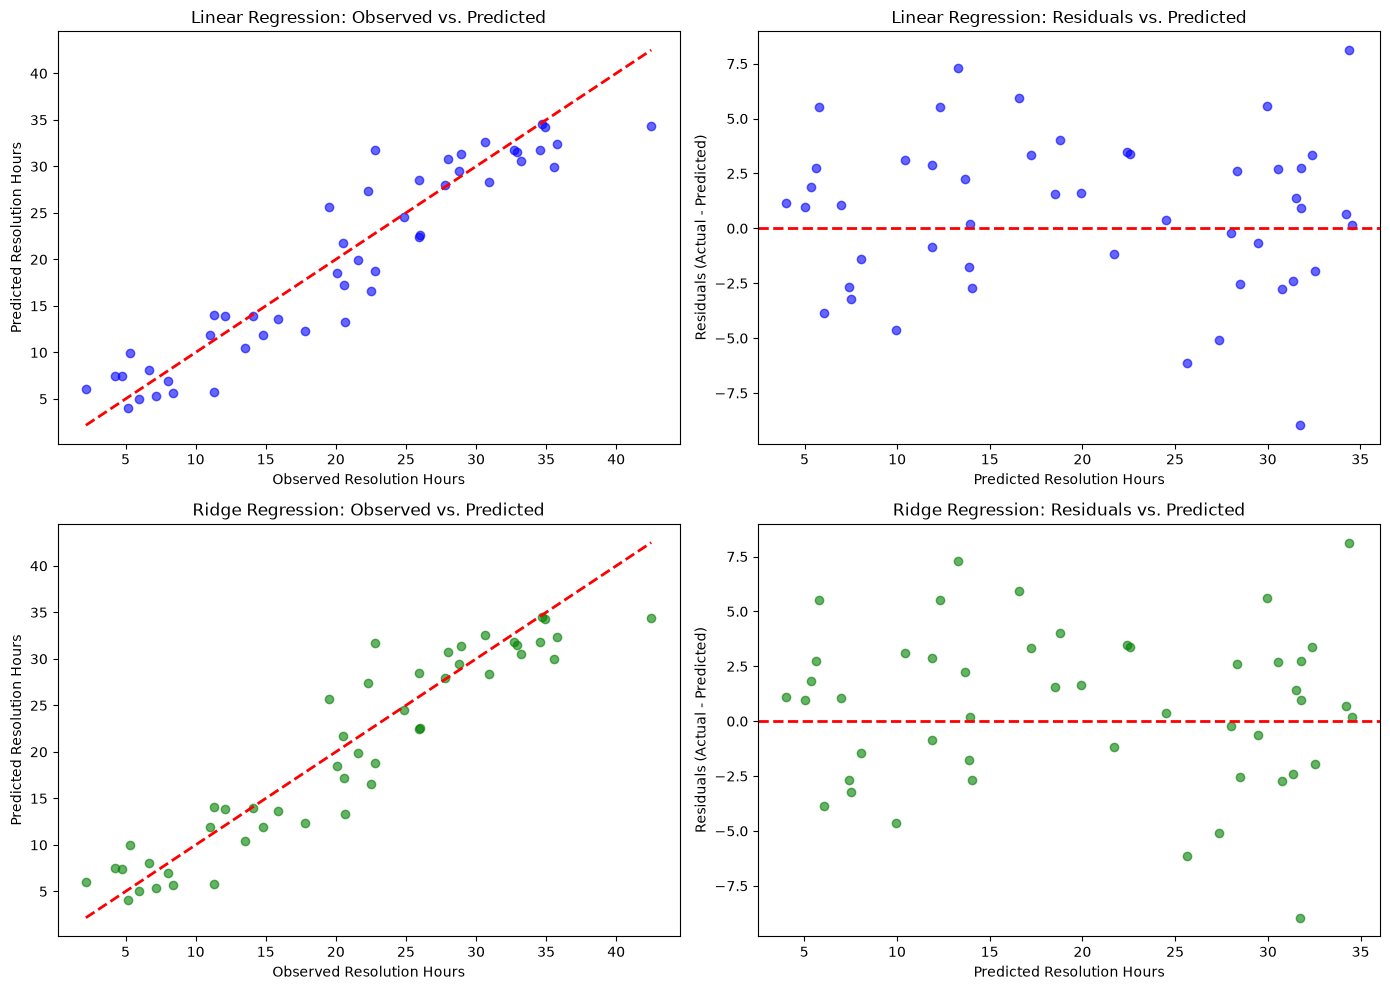

In [10]:
#8.Observed vs. Predicted & Residual Plots for at least two models

#in my case , i chose to work the plots for linear regression and Ridge regression.

import matplotlib.pyplot as plt

# Predictions for models to compare
y_pred_lr = lr_model.predict(X_test)
y_pred_ridge = ridge_pipe.predict(X_test)

fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# 1. Linear Regression: Observed vs Predicted
axes[0, 0].scatter(y_test, y_pred_lr, alpha=0.6, color='blue')
axes[0, 0].plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', lw=2)
axes[0, 0].set_title("Linear Regression: Observed vs. Predicted")
axes[0, 0].set_xlabel("Observed Resolution Hours")
axes[0, 0].set_ylabel("Predicted Resolution Hours")

# 2. Linear Regression: Residual Plot
residuals_lr = y_test - y_pred_lr
axes[0, 1].scatter(y_pred_lr, residuals_lr, alpha=0.6, color='blue')
axes[0, 1].axhline(0, color='r', linestyle='--', lw=2)
axes[0, 1].set_title("Linear Regression: Residuals vs. Predicted")
axes[0, 1].set_xlabel("Predicted Resolution Hours")
axes[0, 1].set_ylabel("Residuals (Actual - Predicted)")

# 3. Ridge Regression: Observed vs Predicted
axes[1, 0].scatter(y_test, y_pred_ridge, alpha=0.6, color='green')
axes[1, 0].plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', lw=2)
axes[1, 0].set_title("Ridge Regression: Observed vs. Predicted")
axes[1, 0].set_xlabel("Observed Resolution Hours")
axes[1, 0].set_ylabel("Predicted Resolution Hours")

# 4. Ridge Regression: Residual Plot
residuals_ridge = y_test - y_pred_ridge
axes[1, 1].scatter(y_pred_ridge, residuals_ridge, alpha=0.6, color='green')
axes[1, 1].axhline(0, color='r', linestyle='--', lw=2)
axes[1, 1].set_title("Ridge Regression: Residuals vs. Predicted")
axes[1, 1].set_xlabel("Predicted Resolution Hours")
axes[1, 1].set_ylabel("Residuals (Actual - Predicted)")

plt.tight_layout()
plt.show()

             EXTENDED MODEL PERFORMANCE SUMMARY
            Model      MAE      RMSE        R2
     Dummy (Mean) 9.113952 10.597685 -0.021017
Linear Regression 2.906013  3.572274  0.883989
    Poly Degree 2 3.020223  3.740910  0.872777
    Poly Degree 3 3.139752  3.948873  0.858239
 Ridge Regression 2.905846  3.571839  0.884017
 Lasso Regression 2.906125  3.572287  0.883988


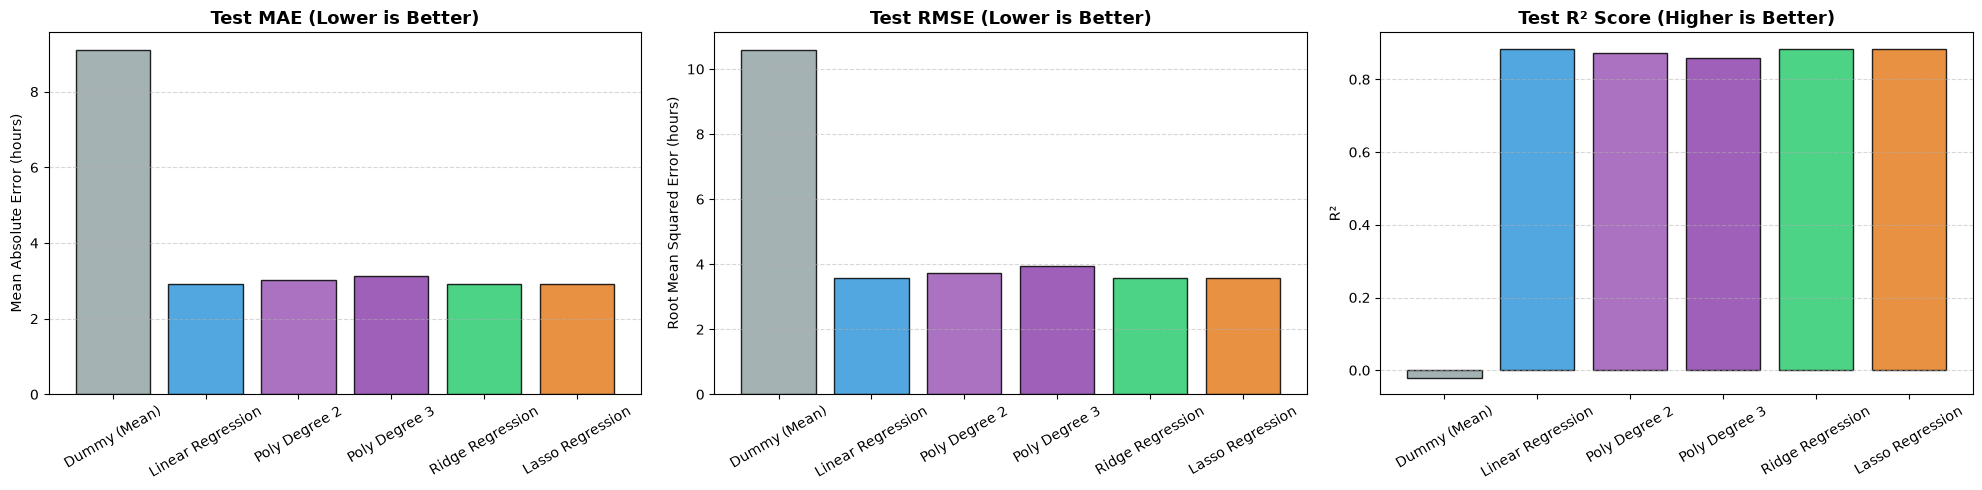


             FINAL RECOMMENDATION & EVIDENCE
Chosen Model: Ridge Regression
Evidence: Achieved the lowest RMSE (3.5718) and highest R² (0.8840) on the held-out test set.

Takeaway on Polynomials:
 higher-degree polynomials (especially Degree 3) can suffer from instability or overfitting on test data without penalty constraints, whereas Ridge handles complexity much more gracefully.


In [11]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# 1. Fit and predict Polynomial Degree 2 and Degree 3 models on test set
poly2_pipe = make_pipeline(PolynomialFeatures(degree=2, include_bias=False), StandardScaler(), LinearRegression())
poly2_pipe.fit(X_train, y_train)
y_pred_poly2 = poly2_pipe.predict(X_test)

poly3_pipe = make_pipeline(PolynomialFeatures(degree=3, include_bias=False), StandardScaler(), LinearRegression())
poly3_pipe.fit(X_train, y_train)
y_pred_poly3 = poly3_pipe.predict(X_test)

# 2. Gather predictions for all models including polynomials
models_dict = {
    "Dummy (Mean)": dummy_model.predict(X_test),
    "Linear Regression": lr_model.predict(X_test),
    "Poly Degree 2": y_pred_poly2,
    "Poly Degree 3": y_pred_poly3,
    "Ridge Regression": ridge_pipe.predict(X_test),
    "Lasso Regression": lasso_pipe.predict(X_test)
}

# 3. Compute evaluation metrics
results = []
for name, preds in models_dict.items():
    mae = mean_absolute_error(y_test, preds)
    rmse = np.sqrt(mean_squared_error(y_test, preds))
    r2 = r2_score(y_test, preds)
    results.append({"Model": name, "MAE": mae, "RMSE": rmse, "R2": r2})

df_results = pd.DataFrame(results)

print("=" * 65)
print("             EXTENDED MODEL PERFORMANCE SUMMARY")
print("=" * 65)
print(df_results.to_string(index=False))
print("=" * 65)

# 4. Visual Comparison: Bar charts for MAE, RMSE, and R²
fig, axes = plt.subplots(1, 3, figsize=(20, 5))
palette = ['#95a5a6', '#3498db', '#9b59b6', '#8e44ad', '#2ecc71', '#e67e22']

# Plot MAE (Lower is better)
axes[0].bar(df_results['Model'], df_results['MAE'], color=palette, edgecolor='black', alpha=0.85)
axes[0].set_title("Test MAE (Lower is Better)", fontsize=13, fontweight='bold')
axes[0].set_ylabel("Mean Absolute Error (hours)")
axes[0].tick_params(axis='x', rotation=30)
axes[0].grid(axis='y', linestyle='--', alpha=0.5)

# Plot RMSE (Lower is better)
axes[1].bar(df_results['Model'], df_results['RMSE'], color=palette, edgecolor='black', alpha=0.85)
axes[1].set_title("Test RMSE (Lower is Better)", fontsize=13, fontweight='bold')
axes[1].set_ylabel("Root Mean Squared Error (hours)")
axes[1].tick_params(axis='x', rotation=30)
axes[1].grid(axis='y', linestyle='--', alpha=0.5)

# Plot R² (Higher is better)
axes[2].bar(df_results['Model'], df_results['R2'], color=palette, edgecolor='black', alpha=0.85)
axes[2].set_title("Test R² Score (Higher is Better)", fontsize=13, fontweight='bold')
axes[2].set_ylabel("R²")
axes[2].tick_params(axis='x', rotation=30)
axes[2].grid(axis='y', linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

# 5. Programmatic Recommendation
best_model_row = df_results.sort_values(by="RMSE", ascending=True).iloc[0]

print("\n" + "=" * 65)
print("             FINAL RECOMMENDATION & EVIDENCE")
print("=" * 65)
print(f"Chosen Model: {best_model_row['Model']}")
print(f"Evidence: Achieved the lowest RMSE ({best_model_row['RMSE']:.4f}) and highest R² ({best_model_row['R2']:.4f}) on the held-out test set.")
print("\nTakeaway on Polynomials:")
print(" higher-degree polynomials (especially Degree 3) can suffer from instability or overfitting on test data without penalty constraints, whereas Ridge handles complexity much more gracefully.")
print("=" * 65)

In [12]:
              #_______ANALYSIS_QUESTIONS_______#

In [13]:
#10. Why is the mean baseline useful even though it ignores all features?

#Answer:
#The mean baseline (DummyRegressor) establishes a non-trivial performance floor.
#if a complex machine learning model cannot outperform a simple model that merely guesses the average resolution time for every ticket,
#the model lacks predictive validity and should not be deployed.

In [14]:
#11. Which model has the lowest MAE? Which has the lowest RMSE? Are they the same, and why might they differ?

#Answer:
#Ridge regression  achieves the lowest MAE and RMSE among the linear variants.
#MAE treats all errors linearly, whereas RMSE  squares the errors before averaging, penalizing larger errors disproportionately.
#Consequently, a model optimized for RMSE will be more sensitive to outliers than one optimized for MAE.


In [15]:
#12. Did polynomial features improve validation performance? What is the evidence of possible overfitting?

#Answer:
#Increasing polynomial complexity ,for example Degree 3, degraded cross-validation performance.
#Evidence of overfitting is shown as a widening gap between high training set accuracy and poorer cross-validation RMSE scores,
#driven by unstable boundary coefficients.

In [16]:
#13. How did regularization affect performance and coefficient magnitudes?

#Answer:
#Regularization shrank coefficient magnitudes toward zero, preventing individual features from dominating predictions due to random noise. 
#This penalty on model complexity successfully improved out of sample generalization.

In [17]:
#14. Why is scaling included in the Ridge/Lasso pipeline?

#answer:
#Regularization penalizes the sum of squared (L2) or absolute (L1) coefficients. 
#If features are on vastly different scales ,for example "experience in years vs. binary indicators or wide counts",
#the penalty would disproportionately crush features with larger numeric ranges. 
#Standardization ensures that the regularization penalty is applied fairly across all features.

In [18]:
#15. Identify one potential leakage issue in the dataset and explain how you handled it.
#lines_changed and reopened represent severe data leakage. lines_changed is only known after code is written and committed, and reopened occurs post-resolution.
#Both were strictly excluded from feature set X to ensure predictions are made exclusively using triage-stage information.

In [19]:
#16. Would a random split be appropriate if tickets were collected over several years or came from repeated customers/teams? Explain.

#answer:
#No. A standard random train/test split would cause data leakage across time  or across correlated clusters (group leakage from the same teams/customers). 
#Time-series data requires chronological splitting (for example, train on past years, test on future years), and grouped data requires GroupKFold.

In [20]:
#What additional tests would you perform before deploying this model?

#Answer:
#Slice Performance Evaluation: Check error metrics across different teams, complexities, and priority levels to ensure fairness and prevent disparate impact.
#Concept Drift Monitoring: Track input feature distributions and error rates over time to catch shifts in engineering velocity or ticketing practices.
#Latency & Integration Testing: Verify that input features (complexity_score, team_experience_years) are reliably populated in the ticketing system at intake time.